# Mini Project 3

## Agaba Steven. 
### Registration Number: S26M19/002. 
### Access Number: B38624

# Lake Victoria Fish Stock and Export Risk Model

In [15]:
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fishstock import (
    FishStock,
    PriceModel
)

from src.riskmodel import (
    RiskAssessment
)

In [16]:
fib = [1, 1]

for _ in range(13):

    fib.append(
        fib[-1] + fib[-2]
    )

fib

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]

## Why Fibonacci Growth is Unrealistic

Fibonacci growth increases indefinitely without considering ecological limits. Real fish populations are constrained by food availability, habitat size, competition, disease, environmental factors, and harvesting activities. Unbounded growth eventually becomes biologically impossible because ecosystems have carrying capacities. Therefore, a logistic growth model provides a more realistic representation of fish-stock dynamics.

In [17]:
harvest_rates = [
    0.05,
    0.10,
    0.20,
    0.30
]

In [18]:
price_model = PriceModel()

prices = price_model.simulate()

prices[:10]

array([12000.        , 12091.41512393, 11779.41989205, 12004.5552508 ,
       12286.72466571, 11701.41410912, 11310.76025706, 11349.11237801,
       11254.23960031, 11249.19925305])

In [19]:
risk_model = RiskAssessment()

In [20]:
scenario_results = []

stock_histories = {}

annual_revenues = []

for h in harvest_rates:

    fish_model = FishStock()

    stock, harvests = fish_model.simulate(
        harvest_rate=h
    )

    revenue = (
        harvests * 1000 * prices
    )

    total_revenue = revenue.sum()

    annual_revenues.append(
        total_revenue
    )

    mean_rev = statistics.mean(
        revenue
    )

    std_rev = statistics.stdev(
        revenue
    )

    cv = std_rev / mean_rev

    risk = risk_model.classify(
        cv
    )

    stock_histories[h] = stock

    scenario_results.append({
        "Harvest Rate": h,
        "Final Stock": stock[-1],
        "Total Revenue": total_revenue,
        "CV": cv,
        "Risk": risk
    })


In [21]:
results_df = pd.DataFrame(
    scenario_results
)

results_df

,Harvest Rate,Final Stock,Total Revenue,CV,Risk
0,0.05,8749.999997,2.639715e+11,0.140123,Low Risk
1,0.10,7499.999925,4.541992e+11,0.126233,Low Risk
2,0.20,4999.987936,6.181812e+11,0.077008,Low Risk
3,0.30,2503.717309,5.144059e+11,0.115064,Low Risk


## Why a Fixed Variance Threshold is Meaningless

Variance is measured in squared units. Revenue is measured in UGX, while variance is measured in UGX². Because variance depends on scale, comparing it against a fixed threshold such as 50,000 has little meaning. The coefficient of variation (CV) is preferable because it standardizes variability relative to the mean, enabling comparison across different revenue levels.

In [22]:
rng = np.random.default_rng(
    42
)

simulated_revenues = []

for _ in range(1000):

    simulated_prices = []

    value = 12000

    for _ in range(52):

        value += rng.normal(
            0,
            300
        )

        value = np.clip(
            value,
            9000,
            16000
        )

        simulated_prices.append(
            value
        )

    simulated_prices = np.array(
        simulated_prices
    )

    fish_model = FishStock()

    stock, harvests = (
        fish_model.simulate(
            harvest_rate=0.10
        )
    )

    revenue = (
        harvests
        * 1000
        * simulated_prices
    )

    simulated_revenues.append(
        revenue.sum()
    )

In [23]:
var_5 = risk_model.value_at_risk(
    simulated_revenues,
    level=5
)

print(
    "5% Value at Risk:",
    round(var_5,2)
)

5% Value at Risk: 376809823253.6


In [24]:
r = 0.4
K = 10000

msy = r * K / 4

print(
    "Maximum Sustainable Yield:",
    msy
)

Maximum Sustainable Yield: 1000.0


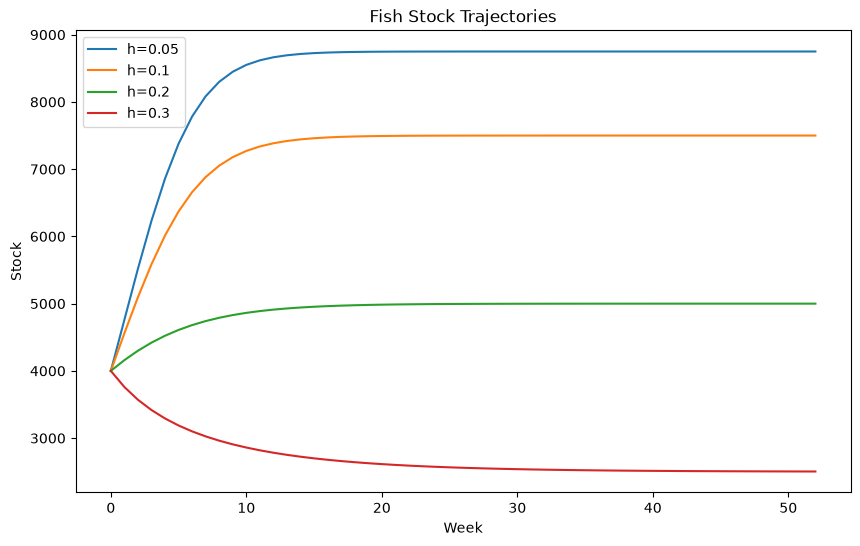

In [25]:
plt.figure(
    figsize=(10,6)
)

for h, stock in (
    stock_histories.items()
):

    plt.plot(
        stock,
        label=f"h={h}"
    )

plt.xlabel("Week")
plt.ylabel("Stock")

plt.title(
    "Fish Stock Trajectories"
)

plt.legend()

plt.show()

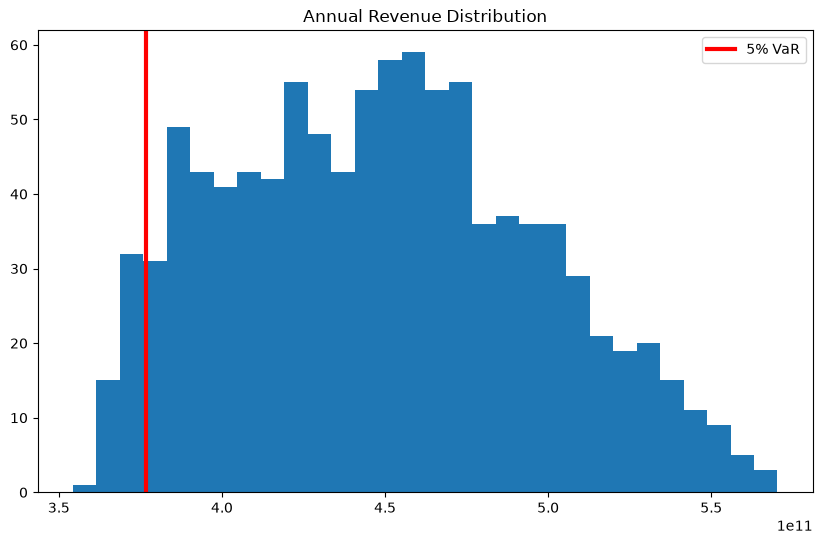

In [26]:
plt.figure(
    figsize=(10,6)
)

plt.hist(
    simulated_revenues,
    bins=30
)

plt.axvline(
    var_5,
    color="red",
    linewidth=3,
    label="5% VaR"
)

plt.legend()

plt.title(
    "Annual Revenue Distribution"
)

plt.show()

In [27]:
five_year_revenues = []

fish_model = FishStock()

stock = fish_model.N0

for year in range(5):

    yearly_revenue = 0

    for week in range(52):

        growth = (
            fish_model.r
            * stock
            * (
                1 -
                stock /
                fish_model.K
            )
        )

        if week < 8:
            harvest = 0
        else:
            harvest = (
                0.10
                * stock
            )

        yearly_revenue += (
            harvest
            * 1000
            * 12000
        )

        stock = (
            stock
            + growth
            - harvest
        )

    five_year_revenues.append(
        yearly_revenue
    )

five_year_revenues

[403201407566.8529,
 404185204977.66064,
 404185204980.3379,
 404185204980.3379,
 404185204980.3379]

## Closed Season Interpretation

The closed season allows fish populations to recover during the first eight weeks of each year. Higher stock levels generally support sustainable harvesting and can improve long-term yields. While revenue is temporarily reduced during the no-harvest period, the larger stock base may improve future earnings and ecological sustainability.

# Findings and Limitations

The logistic growth model produced more realistic fish-stock dynamics than the baseline Fibonacci approach because carrying capacity limits growth. Scenario analysis showed that harvest rate strongly influences long-term stock availability and revenue generation. Lower harvest rates generally preserved larger fish populations, whereas higher harvest rates increased the risk of stock depletion.

Revenue variability was driven largely by fluctuations in fish prices. The coefficient of variation provided a meaningful measure of risk because it standardizes variability relative to average revenue. Monte Carlo simulation generated a distribution of possible annual revenues, enabling estimation of a 5% Value-at-Risk threshold. This quantifies downside financial risk more effectively than arbitrary variance thresholds.

The closed-season extension demonstrated how temporary harvesting restrictions may support population recovery and improve sustainability over longer planning horizons.

A limitation of this study is that fish prices and biological growth are simplified. Real fisheries are influenced by environmental change, regulation, species interactions, illegal fishing activity, and market dynamics. Consequently, the results should be interpreted as planning estimates rather than exact forecasts.